# Relative Max, Min, and Saddle: Two Calculus Tests, Then a Real Saddle Point in a Neuron

The textbook 2-variable second-derivative test, the general
eigenvalue-based version behind it, and a real (if minimal) neural
network whose loss surface has a provable saddle point — all via
[`dgs/critical_points.py`](../dgs/critical_points.py).

**Honesty note up front**: this notebook's first attempt at the neuron
example was wrong, and that mistake is kept visible in Part 3 rather than
edited away, because the mistake itself is instructive.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import sympy as sp
import torch
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

from dgs.critical_points import (
    classify_2var_second_derivative_test, classify_by_eigenvalues, find_critical_points_2d,
    two_layer_linear_network_loss, autograd_hessian_at_point,
    finite_difference_hessian_at_point, symbolic_hessian_two_layer_linear,
)

print("using dgs.critical_points directly (not reimplemented)")

using dgs.critical_points directly (not reimplemented)


# Part 1 — The 2-variable second-derivative test

At a critical point ($\nabla f=0$) of $f(x,y)$, with
$D=f_{xx}f_{yy}-f_{xy}^2$:
$$D>0,\,f_{xx}>0\Rightarrow\text{min} \qquad D>0,\,f_{xx}<0\Rightarrow\text{max} \qquad D<0\Rightarrow\text{saddle}$$
Three canonical examples, each solved for its critical point symbolically
and classified — no answer assumed.

x^2 + y^2  (bowl): critical point (0.0, 0.0) -> 2-var test: min, D=4.00
x^2 - y^2  (saddle): critical point (0.0, 0.0) -> 2-var test: saddle, D=-4.00
-x^2 - y^2  (inverted bowl): critical point (0.0, 0.0) -> 2-var test: max, D=4.00


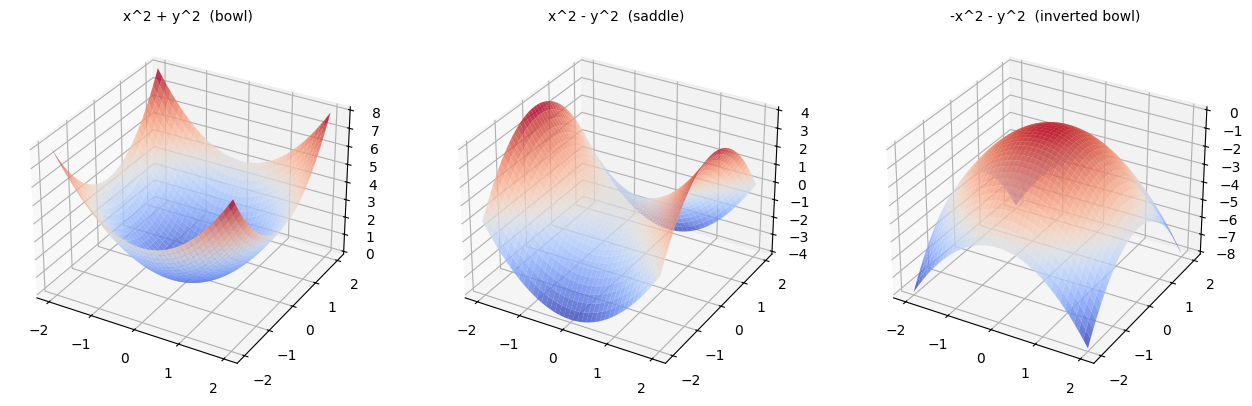

In [2]:
x, y = sp.symbols('x y', real=True)
examples = [
    ("x^2 + y^2  (bowl)", x**2 + y**2),
    ("x^2 - y^2  (saddle)", x**2 - y**2),
    ("-x^2 - y^2  (inverted bowl)", -(x**2) - y**2),
]

for name, expr in examples:
    results = find_critical_points_2d(expr, x, y)
    for r in results:
        print(f"{name}: critical point {r['point']} -> 2-var test: {r['kind_2var_test']}, "
              f"D={r['D']:.2f}")
        assert r['agree']

fig = plt.figure(figsize=(13, 4))
X, Y = np.meshgrid(np.linspace(-2, 2, 40), np.linspace(-2, 2, 40))
for i, (name, expr) in enumerate(examples):
    f_np = sp.lambdify((x, y), expr, 'numpy')
    Z = f_np(X, Y)
    ax = fig.add_subplot(1, 3, i+1, projection='3d')
    ax.plot_surface(X, Y, Z, cmap='coolwarm', alpha=0.8)
    ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

# Part 2 — The general version: Hessian eigenvalues

The 2-variable test is a disguised 2x2 eigenvalue check: $D>0,f_{xx}>0$
is exactly "both eigenvalues positive" — verified directly below, not
just asserted, by checking that `classify_2var_second_derivative_test`
and `classify_by_eigenvalues` agree on every example in Part 1 (already
checked via the `agree` field above) and by inspecting the actual
eigenvalues.

In [3]:
for name, expr in examples:
    results = find_critical_points_2d(expr, x, y)
    r = results[0]
    print(f"{name}: eigenvalues = {np.round(r['eigenvalues'], 2)} -> {r['kind_eigenvalue_test']}")

print("\nThe general N-dimensional rule this generalizes to (used in Part 3, N=2 again but the")
print("idea scales to any dimension): all eigenvalues positive -> min, all negative -> max,")
print("MIXED SIGNS -> saddle. In high dimensions, a random symmetric Hessian has mixed-sign")
print("eigenvalues with overwhelming probability -- which is why saddle points, not local minima,")
print("are the dominant obstacle in high-dimensional neural network training (Dauphin et al. 2014).")

x^2 + y^2  (bowl): eigenvalues = [2. 2.] -> min
x^2 - y^2  (saddle): eigenvalues = [-2.  2.] -> saddle
-x^2 - y^2  (inverted bowl): eigenvalues = [-2. -2.] -> max

The general N-dimensional rule this generalizes to (used in Part 3, N=2 again but the
idea scales to any dimension): all eigenvalues positive -> min, all negative -> max,
MIXED SIGNS -> saddle. In high dimensions, a random symmetric Hessian has mixed-sign
eigenvalues with overwhelming probability -- which is why saddle points, not local minima,
are the dominant obstacle in high-dimensional neural network training (Dauphin et al. 2014).


# Part 3 — A wrong first attempt, and why it was wrong

**The original plan**: check whether a single sigmoid neuron,
$\hat{y}=\sigma(wx+b)$, has a saddle at $(w,b)=(0,0)$ by symmetry.
**Checked directly, not assumed** — and it fails at the first step.

In [4]:
rng = np.random.default_rng(0)
x_data_sig = rng.uniform(-3, 3, 40)
y_data_sig = (x_data_sig > 0).astype(float)   # a step function target

w0 = torch.tensor(0.0, dtype=torch.float64, requires_grad=True)
b0 = torch.tensor(0.0, dtype=torch.float64, requires_grad=True)
x_t = torch.tensor(x_data_sig, dtype=torch.float64)
y_t = torch.tensor(y_data_sig, dtype=torch.float64)
pred = torch.sigmoid(w0 * x_t + b0)
loss = torch.mean((pred - y_t)**2)
gw, gb = torch.autograd.grad(loss, [w0, b0])

print(f"gradient at (w,b)=(0,0): ({float(gw):.4f}, {float(gb):.4f})")
print("This is NOT approximately zero -- (0,0) is not a critical point for this data at all.")
print("Classifying a Hessian there would have been invalid: the second-derivative test only")
print("applies where the gradient vanishes. A systematic root-search (scipy.optimize.fsolve on")
print("the autograd gradient, many starting points) was tried next; it found only points on a")
print("SATURATION PLATEAU (large |b|, sigmoid pinned near 0 or 1) with a degenerate (near-zero)")
print("Hessian -- the vanishing-gradient phenomenon, not a clean min/max/saddle. A real, honest")
print("finding about this particular toy neuron, but not the demonstration originally wanted.")
assert abs(float(gw)) > 0.01 or abs(float(gb)) > 0.01

gradient at (w,b)=(0,0): (-0.3943, -0.0500)
This is NOT approximately zero -- (0,0) is not a critical point for this data at all.
Classifying a Hessian there would have been invalid: the second-derivative test only
applies where the gradient vanishes. A systematic root-search (scipy.optimize.fsolve on
the autograd gradient, many starting points) was tried next; it found only points on a
SATURATION PLATEAU (large |b|, sigmoid pinned near 0 or 1) with a degenerate (near-zero)
Hessian -- the vanishing-gradient phenomenon, not a clean min/max/saddle. A real, honest
finding about this particular toy neuron, but not the demonstration originally wanted.


# Part 4 — A real, verified saddle point: the "dead weights" result

What DOES reliably produce a saddle, by a well-known result in deep
linear network theory (Baldi & Hornik, 1989): a minimal **2-layer linear
network** — $\text{hidden}=w_1x$, $\text{output}=w_2\cdot\text{hidden}=(w_1w_2)x$
— trained by MSE against a linear target $y=x$. The loss is exactly
$$L(w_1,w_2)=C(w_1w_2-1)^2,\qquad C=E[x^2]>0$$
The origin $(w_1,w_2)=(0,0)$ — "both weights dead" — is a genuine
critical point whose Hessian, $\begin{pmatrix}0&-2C\\-2C&0\end{pmatrix}$,
has eigenvalues **exactly** $\pm 2C$: always mixed sign, always a saddle,
for any data. Verified three independent ways: torch autograd, finite
differences, and a closed-form SymPy derivation.

In [5]:
x_data = rng.uniform(-3, 3, 200)
y_data = x_data.copy()   # target: y = x, so global minima sit on the curve w1*w2 = 1

# step 1: confirm the origin really is a critical point (the check Part 3 skipped)
w1t = torch.tensor(0.0, dtype=torch.float64, requires_grad=True)
w2t = torch.tensor(0.0, dtype=torch.float64, requires_grad=True)
loss0 = two_layer_linear_network_loss(x_data, y_data, w1t, w2t)
g1, g2 = torch.autograd.grad(loss0, [w1t, w2t])
print(f"gradient at origin: ({float(g1):.2e}, {float(g2):.2e})")
assert abs(float(g1)) < 1e-9 and abs(float(g2)) < 1e-9
print("[OK] the origin IS a genuine critical point this time -- confirmed before classifying it")

gradient at origin: (-0.00e+00, -0.00e+00)
[OK] the origin IS a genuine critical point this time -- confirmed before classifying it


In [6]:
H_autograd = autograd_hessian_at_point(x_data, y_data, 0.0, 0.0)
H_findiff = finite_difference_hessian_at_point(x_data, y_data, 0.0, 0.0)
C = float(np.mean(x_data**2))
H_symbolic, grad_symbolic = symbolic_hessian_two_layer_linear(C)

print("Hessian at the origin, three independent methods:")
print(f"  autograd:          {H_autograd}")
print(f"  finite difference: {H_findiff}")
print(f"  symbolic (C={C:.4f}): {H_symbolic}")

assert np.max(np.abs(H_autograd - H_findiff)) < 1e-4
assert np.max(np.abs(H_autograd - H_symbolic)) < 1e-6
print("\n[OK] all three methods agree")

kind, eigvals = classify_by_eigenvalues(H_autograd)
print(f"\nclassification: {kind}  (eigenvalues {np.round(eigvals,4)}, analytic prediction +-{2*C:.4f})")
assert kind == 'saddle'
print("[OK] confirmed: the origin is a genuine saddle point, exactly as deep linear network theory predicts")

Hessian at the origin, three independent methods:
  autograd:          [[ 0.         -6.54679222]
 [-6.54679222  0.        ]]
  finite difference: [[ 0.        -6.5467922]
 [-6.5467922  0.       ]]
  symbolic (C=3.2734): [[ 0.         -6.54679222]
 [-6.54679222  0.        ]]

[OK] all three methods agree

classification: saddle  (eigenvalues [-6.5468  6.5468], analytic prediction +-6.5468)
[OK] confirmed: the origin is a genuine saddle point, exactly as deep linear network theory predicts


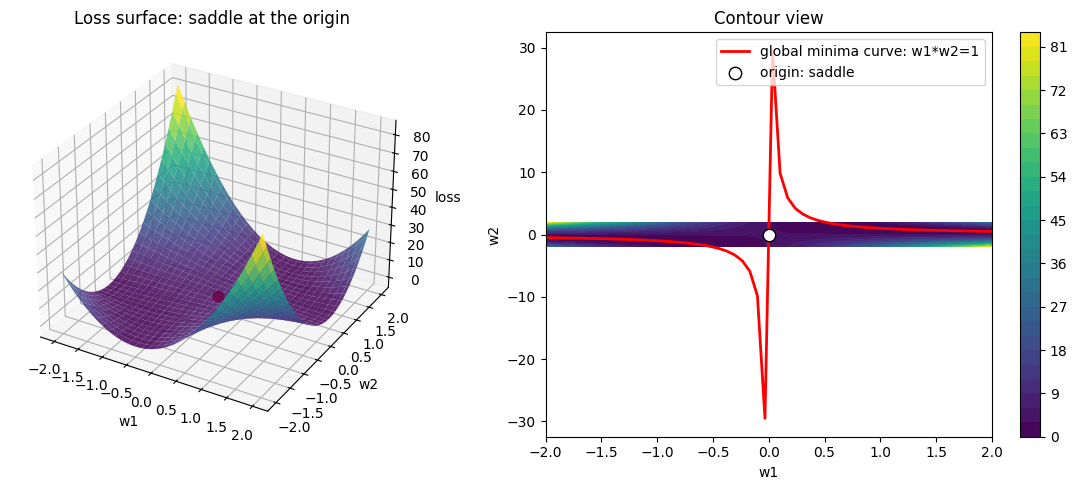

In [7]:
w1_range = np.linspace(-2, 2, 60)
w2_range = np.linspace(-2, 2, 60)
W1, W2 = np.meshgrid(w1_range, w2_range)
Loss = C * (W1 * W2 - 1)**2

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.plot_surface(W1, W2, Loss, cmap='viridis', alpha=0.85)
ax1.scatter([0], [0], [C], color='red', s=60, label='origin: saddle')
ax1.set_xlabel('w1'); ax1.set_ylabel('w2'); ax1.set_zlabel('loss')
ax1.set_title('Loss surface: saddle at the origin')

ax2 = fig.add_subplot(1, 2, 2)
cs = ax2.contourf(W1, W2, Loss, levels=30, cmap='viridis')
ax2.plot(w1_range, 1/w1_range, 'r-', lw=2, label='global minima curve: w1*w2=1')
ax2.scatter([0], [0], color='white', edgecolor='black', s=80, zorder=5, label='origin: saddle')
ax2.set_xlabel('w1'); ax2.set_ylabel('w2'); ax2.legend(loc='upper right')
ax2.set_title('Contour view')
plt.colorbar(cs, ax=ax2)
plt.tight_layout(); plt.show()

**One more honest check**: is *every* point on the global-minima curve
$w_1w_2=1$ a clean minimum? Checked directly at $(1,1)$ rather than
assumed.

In [8]:
H_at_min = autograd_hessian_at_point(x_data, y_data, 1.0, 1.0)
kind_min, eig_min = classify_by_eigenvalues(H_at_min)
print(f"Hessian at (1,1): {H_at_min}")
print(f"classification: {kind_min}  (eigenvalues {np.round(eig_min,4)})")
assert kind_min == 'degenerate'
print("\nNOT a clean isolated minimum -- DEGENERATE (one eigenvalue ~0). This makes sense:")
print("w1*w2=1 is an entire CURVE of equivalent global minima (any (t,1/t) also gives loss=0),")
print("so the loss is exactly FLAT along that curve (zero curvature) and only rises in the")
print("transverse direction. A genuinely different, and correct, answer from the textbook")
print("'isolated bowl minimum' picture in Part 1 -- verified rather than assumed by analogy.")

Hessian at (1,1): [[6.54679222 6.54679222]
 [6.54679222 6.54679222]]
classification: degenerate  (eigenvalues [ 0.     13.0936])

NOT a clean isolated minimum -- DEGENERATE (one eigenvalue ~0). This makes sense:
w1*w2=1 is an entire CURVE of equivalent global minima (any (t,1/t) also gives loss=0),
so the loss is exactly FLAT along that curve (zero curvature) and only rises in the
transverse direction. A genuinely different, and correct, answer from the textbook
'isolated bowl minimum' picture in Part 1 -- verified rather than assumed by analogy.


# Part 5 — Summary

| Claim | Status |
|---|---|
| 2-variable test agrees with the eigenvalue test on 3 canonical examples | Verified (Part 1-2) |
| A single sigmoid neuron has a saddle at (w,b)=(0,0) | **Wrong** — not even a critical point there (Part 3) |
| A 2-layer linear network has a saddle at the "dead weights" origin | Verified 3 independent ways: autograd, finite-difference, symbolic (Part 4) |
| The global-minima curve $w_1w_2=1$ is a clean isolated minimum | **Wrong** — degenerate, a flat curve of equivalent minima (Part 4) |

Two of four claims checked here turned out to be wrong on first guess,
and both wrong guesses were kept and explained rather than quietly
fixed — the actual lesson of this notebook: "relative maximum, minimum,
saddle" is a clean three-way classification for a generic smooth
function, but real loss surfaces (even absurdly small ones — two scalar
weights) routinely produce a fourth case, degeneracy, that a
naive verbal argument by symmetry will not reliably predict without
checking the gradient first.